<a href="https://colab.research.google.com/github/andikeke88-del/PDS-KEYSHA/blob/main/regresi_kota_makassar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset berhasil dibaca dari GitHub!
Jumlah seluruh data: 1067

Kota yang dianalisis: Kota Makassar
Jumlah observasi: 11
Periode: 2014-2024


,Kota,Tahun,IPM,DAK_Nonfisik,DBH_SDA
0,Kota Makassar,2014,80.83,167.07,135.65
1,Kota Makassar,2015,60.64,105.43,138.85
2,Kota Makassar,2016,71.88,163.10,110.87
3,Kota Makassar,2017,75.65,215.66,156.24
4,Kota Makassar,2018,84.24,232.94,126.27
5,Kota Makassar,2019,62.51,133.91,107.17
6,Kota Makassar,2020,62.30,144.49,79.51
7,Kota Makassar,2021,75.22,183.97,155.91
8,Kota Makassar,2022,72.38,153.54,116.77
9,Kota Makassar,2023,81.59,172.39,172.69


Model 2D-A: IPM ~ DAK_Nonfisik
Persamaan regresi:
IPM = 42.3502 + 0.1820*DAK_Nonfisik
R²            = 0.6625 (66.25%)
Adjusted R²   = 0.6251
RMSE          = 4.5399
Koefisien:
  Intercept         : 42.350229
  DAK_Nonfisik      : 0.182004

Model 2D-B: IPM ~ DBH_SDA
Persamaan regresi:
IPM = 56.0760 + 0.1213*DBH_SDA
R²            = 0.1844 (18.44%)
Adjusted R²   = 0.0938
RMSE          = 7.0577
Koefisien:
  Intercept         : 56.075970
  DBH_SDA           : 0.121316

Model 3D: IPM ~ DAK_Nonfisik + DBH_SDA
Persamaan regresi:
IPM = 34.1042 + 0.1694*DAK_Nonfisik + 0.0772*DBH_SDA
R²            = 0.7340 (73.40%)
Adjusted R²   = 0.6675
RMSE          = 4.0304
Koefisien:
  Intercept         : 34.104222
  DAK_Nonfisik      : 0.169405
  DBH_SDA           : 0.077186



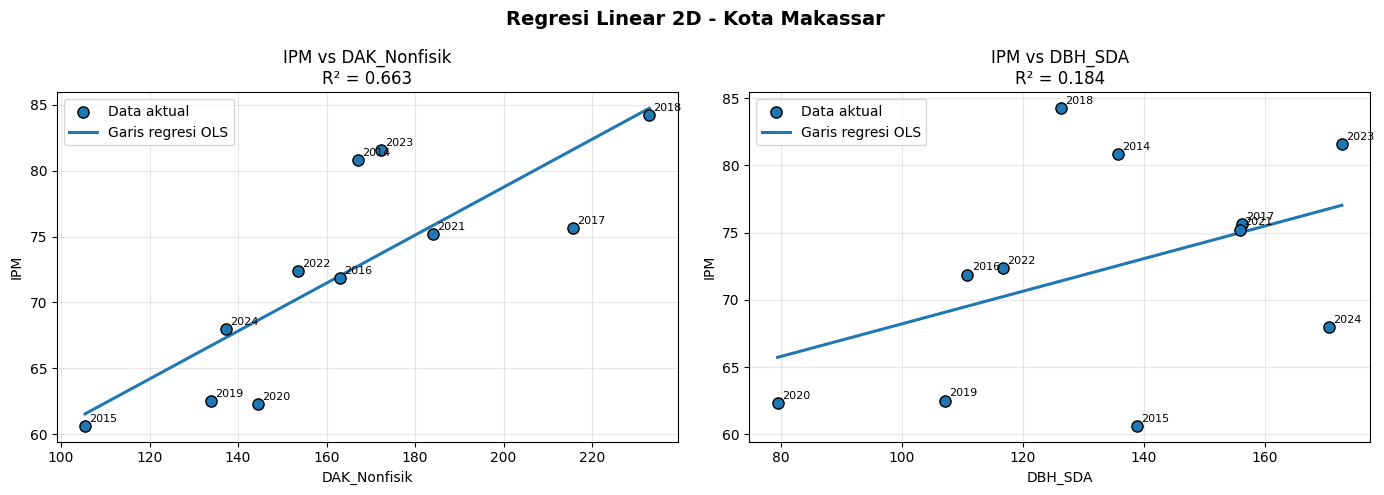

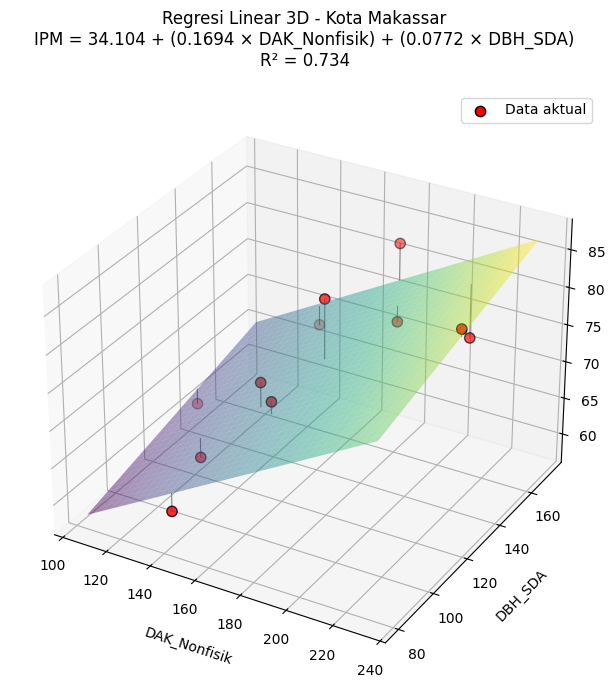

Tabel perbandingan IPM aktual dan hasil prediksi model 3D:


,Tahun,IPM,DAK_Nonfisik,DBH_SDA,IPM_Prediksi_3D,Residual
0,2014,80.83,167.07,135.65,72.8770,7.9530
1,2015,60.64,105.43,138.85,62.6819,-2.0419
2,2016,71.88,163.10,110.87,70.2918,1.5882
3,2017,75.65,215.66,156.24,82.6977,-7.0477
4,2018,84.24,232.94,126.27,83.3118,0.9282
5,2019,62.51,133.91,107.17,65.0613,-2.5513
6,2020,62.30,144.49,79.51,64.7186,-2.4186
7,2021,75.22,183.97,155.91,77.3038,-2.0838
8,2022,72.38,153.54,116.77,69.1277,3.2523
9,2023,81.59,172.39,172.69,76.6372,4.9528


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

# 1. MEMBACA DATASET DARI GITHUB
FILE = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/refs/heads/main/dataset_fiskal_97_hipoFull.csv"

df = pd.read_csv(FILE)

print("Dataset berhasil dibaca dari GitHub!")
print("Jumlah seluruh data:", len(df))

# 2. PILIH KOTA DAN VARIABEL
KOTA = "Kota Makassar"
Y = "IPM"
X1 = "DAK_Nonfisik"
X2 = "DBH_SDA"

kolom_wajib = ["Kota", "Tahun", Y, X1, X2]
kolom_hilang = [c for c in kolom_wajib if c not in df.columns]

if kolom_hilang:
    raise ValueError(f"Kolom tidak ditemukan: {kolom_hilang}")

df["Kota"] = df["Kota"].astype(str).str.strip()

data = df.loc[
    df["Kota"].str.casefold() == KOTA.casefold(),
    ["Kota", "Tahun", Y, X1, X2]
].copy()

if data.empty:
    raise ValueError(f"Data {KOTA} tidak ditemukan.")

for kolom in ["Tahun", Y, X1, X2]:
    data[kolom] = pd.to_numeric(data[kolom], errors="coerce")

jumlah_sebelum = len(data)

data = (
    data.dropna(subset=["Tahun", Y, X1, X2])
    .sort_values("Tahun")
    .reset_index(drop=True)
)

if len(data) < 4:
    raise ValueError("Data valid terlalu sedikit untuk regresi.")

if data[[Y, X1, X2]].nunique().min() < 2:
    raise ValueError("Ada variabel yang nilainya konstan.")

print(f"\nKota yang dianalisis: {KOTA}")
print(f"Jumlah observasi: {len(data)}")
print(f"Periode: {int(data['Tahun'].min())}-{int(data['Tahun'].max())}")

if jumlah_sebelum > len(data):
    print("Baris dengan data tidak valid diabaikan:",
          jumlah_sebelum - len(data))

display(data)

# 3. FUNGSI REGRESI OLS DENGAN NUMPY
# Persamaan umum: Y = b0 + b1*X1 (+ b2*X2)
def regresi_ols(X, y, nama_model):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)

    # Tambahkan kolom 1 untuk intercept/konstanta
    A = np.column_stack((np.ones(len(y)), X))
    koef, _, rank, _ = np.linalg.lstsq(A, y, rcond=None)
    if rank < A.shape[1]:
        raise ValueError(f"{nama_model}: variabel bebas memiliki hubungan linear sempurna.")

    prediksi = A @ koef
    residual = y - prediksi
    sse = float(np.sum(residual ** 2))
    sst = float(np.sum((y - np.mean(y)) ** 2))
    if np.isclose(sst, 0):
        raise ValueError("IPM konstan sehingga R² tidak dapat dihitung.")

    r2 = 1 - sse / sst
    n = len(y)
    jumlah_parameter = A.shape[1]
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - jumlah_parameter)
    rmse = np.sqrt(np.mean(residual ** 2))

    return {
        "nama": nama_model,
        "koef": koef,
        "prediksi": prediksi,
        "residual": residual,
        "r2": r2,
        "adjusted_r2": adjusted_r2,
        "rmse": rmse
    }

# Siapkan variabel
Y_data = data[Y].to_numpy(dtype=float)
X1_data = data[X1].to_numpy(dtype=float)
X2_data = data[X2].to_numpy(dtype=float)
tahun = data["Tahun"].to_numpy(dtype=int)

# 4. ESTIMASI MODEL 2D DAN MODEL 3D
# Model 2D-A: IPM dijelaskan oleh DAK_Nonfisik
model_2d_a = regresi_ols(X1_data, Y_data, f"Model 2D-A: {Y} ~ {X1}")
# Model 2D-B: IPM dijelaskan oleh DBH_SDA
model_2d_b = regresi_ols(X2_data, Y_data, f"Model 2D-B: {Y} ~ {X2}")
# Model 3D: IPM dijelaskan oleh DAK_Nonfisik dan DBH_SDA sekaligus
model_3d = regresi_ols(np.column_stack((X1_data, X2_data)), Y_data,
                       f"Model 3D: {Y} ~ {X1} + {X2}")

def tampilkan_hasil(model, nama_variabel):
    print("=" * 68)
    print(model["nama"])
    print("=" * 68)
    print("Persamaan regresi:")
    persamaan = f"{Y} = {model['koef'][0]:.4f}"
    for b, nama in zip(model["koef"][1:], nama_variabel):
        tanda = "+" if b >= 0 else "-"
        persamaan += f" {tanda} {abs(b):.4f}*{nama}"
    print(persamaan)
    print(f"R²            = {model['r2']:.4f} ({model['r2']*100:.2f}%)")
    print(f"Adjusted R²   = {model['adjusted_r2']:.4f}")
    print(f"RMSE          = {model['rmse']:.4f}")
    print("Koefisien:")
    for nama, nilai in zip(["Intercept"] + nama_variabel, model["koef"]):
        print(f"  {nama:<18}: {nilai:.6f}")
    print()

tampilkan_hasil(model_2d_a, [X1])
tampilkan_hasil(model_2d_b, [X2])
tampilkan_hasil(model_3d, [X1, X2])

# 5. VISUALISASI REGRESI 2D
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, model, nama_x in [
    (axes[0], X1_data, model_2d_a, X1),
    (axes[1], X2_data, model_2d_b, X2)
]:
    ax.scatter(x, Y_data, s=65, edgecolor="black", label="Data aktual", zorder=3)
    urutan = np.argsort(x)
    garis_y = model["koef"][0] + model["koef"][1] * x[urutan]
    ax.plot(x[urutan], garis_y, linewidth=2.2, label="Garis regresi OLS")
    for xi, yi, th in zip(x, Y_data, tahun):
        ax.annotate(str(th), (xi, yi), fontsize=8, xytext=(3, 3),
                    textcoords="offset points")
    ax.set_xlabel(nama_x)
    ax.set_ylabel(Y)
    ax.set_title(f"{Y} vs {nama_x}\nR² = {model['r2']:.3f}")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.suptitle(f"Regresi Linear 2D - {KOTA}", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 6. VISUALISASI REGRESI 3D (BIDANG REGRESI)
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")
b0, b1, b2 = model_3d["koef"]

rentang_x1 = np.linspace(X1_data.min(), X1_data.max(), 35)
rentang_x2 = np.linspace(X2_data.min(), X2_data.max(), 35)
G1, G2 = np.meshgrid(rentang_x1, rentang_x2)
G_Y = b0 + b1 * G1 + b2 * G2

ax.plot_surface(G1, G2, G_Y, cmap="viridis", alpha=0.45, edgecolor="none")
ax.scatter(X1_data, X2_data, Y_data, color="red", s=55,
           edgecolor="black", label="Data aktual")

# Garis vertikal menunjukkan selisih IPM aktual dan prediksi model 3D
for xa, xb, aktual, pred in zip(X1_data, X2_data, Y_data, model_3d["prediksi"]):
    ax.plot([xa, xa], [xb, xb], [aktual, pred], color="gray", linewidth=0.8)

ax.set_xlabel(X1, labelpad=9)
ax.set_ylabel(X2, labelpad=9)
ax.set_zlabel(Y, labelpad=7)
ax.set_title(
    f"Regresi Linear 3D - {KOTA}\n"
    f"IPM = {b0:.3f} + ({b1:.4f} × {X1}) + ({b2:.4f} × {X2})\n"
    f"R² = {model_3d['r2']:.3f}",
    pad=18
)
ax.legend()
plt.tight_layout()
plt.show()

# 7. TABEL IPM AKTUAL DAN PREDIKSI MODEL 3D
hasil_prediksi = data[["Tahun", Y, X1, X2]].copy()
hasil_prediksi["IPM_Prediksi_3D"] = model_3d["prediksi"]
hasil_prediksi["Residual"] = model_3d["residual"]
print("Tabel perbandingan IPM aktual dan hasil prediksi model 3D:")
display(hasil_prediksi.round(4))

